# 架空ECサイトの売上向上を目的としたデータ分析・マーケティング施策提案

## 分析の目的
売上の変動を注文数・平均注文単価に分解し、商品カテゴリや顧客の購入回数を分析することで、売上・利益向上に向けた施策の仮説を立てる。

## 使用データ・ツール
- データ：BigQuery公開データセット「TheLook eCommerce」（架空ECデータ）
- SQL（BigQuery）：注文明細と商品情報の結合・抽出・集計
- Python（pandas・Matplotlib）：品質確認・加工・分析・可視化
- Tableau Public：ダッシュボード作成

## 集計条件
- 対象期間：2025年9月1日以上、2026年9月1日未満
- 日付基準：注文明細の作成日時（UTC）
- 売上：ステータスがCompleteの明細の販売価格合計
- 注文数：対象明細に含まれる注文IDの重複を除いた件数
- 参考粗利：販売価格－商品原価（広告費・送料等は含まない）
- 金額：元データの値を使用し、通貨換算は行わない

## 分析上の注意
- 架空データのため、実在する企業の業績を示すものではない。
- 購入回数は分析期間内の完了注文に限り、生涯の購入回数や新規・既存顧客の区分とは異なる。
- 分析から施策の仮説を提案するものであり、施策の効果を実証したものではない。

In [1]:
import pandas as pd
from google.colab import files

uploaded = files.upload()

df = pd.read_csv("order_items_detail.csv")

print(f"行数：{df.shape[0]:,}行")
print(f"列数：{df.shape[1]}列")

display(df.head())

Saving order_items_detail.csv to order_items_detail.csv
行数：64,400行
列数：9列


,order_item_id,order_id,user_id,product_id,created_at,status,sale_price,category,product_cost
0,92836,64043,51249,28340,2025-09-01 00:10:21 UTC,Shipped,7.990000,Accessories,2.820470
1,93563,64556,51670,15966,2025-09-01 00:16:08 UTC,Cancelled,32.000000,Plus,16.896000
2,68364,47272,37799,8359,2025-09-01 00:33:10 UTC,Shipped,139.990005,Outerwear & Coats,68.595102
3,14147,9787,7884,10838,2025-09-01 00:33:49 UTC,Shipped,12.990000,Intimates,6.495000
4,69681,48173,38501,19672,2025-09-01 00:44:15 UTC,Shipped,45.000000,Sweaters,24.525000


In [2]:
# カラムごとの欠損数を確認
print("【カラムごとの欠損数】")
display(df.isna().sum())

# 明細IDの重複を確認
print("【明細IDの重複数】")
print(df["order_item_id"].duplicated().sum())

# 状態ごとの明細数を確認
print("【状態ごとの明細数】")
display(df["status"].value_counts(dropna=False))

【カラムごとの欠損数】


,0
order_item_id,0
order_id,0
user_id,0
product_id,0
created_at,0
status,0
sale_price,0
category,0
product_cost,0


【明細IDの重複数】
0
【状態ごとの明細数】


,count
status,
Shipped,19181
Complete,16301
Processing,12994
Cancelled,9470
Returned,6454


In [3]:
# 元データを残し、加工用のコピーを作る
df_clean = df.copy()

# 日時として扱える形式に変換する（UTC基準）
df_clean["created_at"] = pd.to_datetime(
    df_clean["created_at"],
    format="mixed",
    utc=True,
    errors="coerce"
)

# 販売価格と原価を数値に変換する
for col in ["sale_price", "product_cost"]:
    df_clean[col] = pd.to_numeric(
        df_clean[col],
        errors="coerce"
    )

# 変換できなかった値がないか確認する
print("【変換後の欠損数】")
display(
    df_clean[
        ["created_at", "sale_price", "product_cost"]
    ].isna().sum()
)

# 分析期間から外れた日時を確認する
start = pd.Timestamp("2025-09-01", tz="UTC")
end = pd.Timestamp("2026-09-01", tz="UTC")

outside_period = (
    (df_clean["created_at"] < start)
    | (df_clean["created_at"] >= end)
)

print("【分析期間外の明細数】")
print(outside_period.sum())

# 金額がマイナスになっていないか確認する
print("【マイナスの金額の件数】")
display(
    (df_clean[["sale_price", "product_cost"]] < 0).sum()
)

【変換後の欠損数】


,0
created_at,0
sale_price,0
product_cost,0


【分析期間外の明細数】
0
【マイナスの金額の件数】


,0
sale_price,0
product_cost,0


In [4]:
# 完了した明細だけを取り出す
completed = df_clean[
    df_clean["status"] == "Complete"
].copy()

# 明細ごとの参考粗利を計算する
completed["gross_profit"] = (
    completed["sale_price"] - completed["product_cost"]
)

# 全期間の売上と参考粗利を合計する
total_sales = completed["sale_price"].sum()
total_gross_profit = completed["gross_profit"].sum()

print(f"完了明細数：{len(completed):,}行")
print(f"売上合計：{total_sales:,.2f}")
print(f"参考粗利合計：{total_gross_profit:,.2f}")

# 保存済みのSQL集計結果と照合する
sql_sales = 963310.83
sql_gross_profit = 499877.33

print("【SQLの結果との差額】")
print(f"売上差額：{total_sales - sql_sales:,.2f}")
print(f"参考粗利差額：{total_gross_profit - sql_gross_profit:,.2f}")

完了明細数：16,301行
売上合計：963,310.83
参考粗利合計：499,877.32
【SQLの結果との差額】
売上差額：0.00
参考粗利差額：-0.01


In [5]:
# 明細作成日時から「年月」を取り出す（UTC基準）
completed["sales_month"] = (
    completed["created_at"].dt.strftime("%Y-%m")
)

# 月ごとに集計する
monthly = completed.groupby("sales_month").agg(
    order_count=("order_id", "nunique"),
    item_count=("order_item_id", "count"),
    sales=("sale_price", "sum"),
    gross_profit=("gross_profit", "sum")
).reset_index()

# 平均注文単価と粗利率を計算する
monthly["average_order_value"] = (
    monthly["sales"] / monthly["order_count"]
)

monthly["gross_margin_pct"] = (
    monthly["gross_profit"] / monthly["sales"] * 100
)

# 表示するときだけ小数第2位までに丸める
display(monthly.round(2))

,sales_month,order_count,item_count,sales,gross_profit,average_order_value,gross_margin_pct
0,2025-09,681,980,59419.12,31117.13,87.25,52.37
1,2025-10,761,1086,64191.72,33120.53,84.35,51.60
2,2025-11,736,1053,62221.76,32491.39,84.54,52.22
3,2025-12,748,1088,60975.71,31417.44,81.52,51.52
4,2026-01,831,1194,72002.03,37566.28,86.65,52.17
5,2026-02,748,1057,60476.92,31407.20,80.85,51.93
6,2026-03,943,1338,77375.86,39946.61,82.05,51.63
7,2026-04,958,1345,78374.21,40741.38,81.81,51.98
8,2026-05,1045,1500,89018.05,46107.11,85.18,51.80
9,2026-06,1099,1551,88992.52,45913.37,80.98,51.59


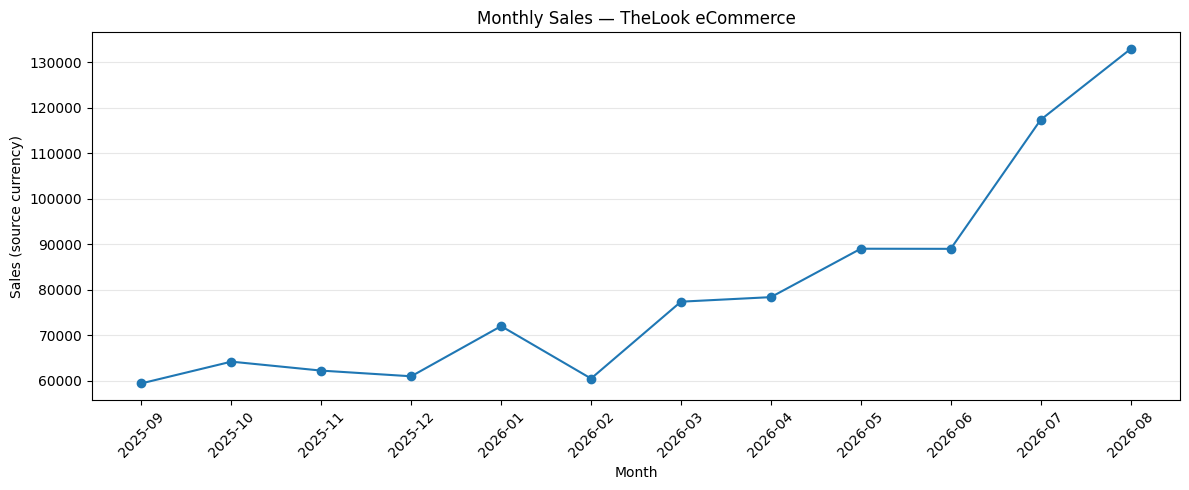

In [6]:
import matplotlib.pyplot as plt

# グラフの大きさを設定する
plt.figure(figsize=(12, 5))

# 横軸に年月、縦軸に売上を指定する
plt.plot(
    monthly["sales_month"],
    monthly["sales"],
    marker="o"
)

# タイトルと軸の名前を付ける
plt.title("Monthly Sales — TheLook eCommerce")
plt.xlabel("Month")
plt.ylabel("Sales (source currency)")

# 目盛りとレイアウトを整える
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# グラフを表示する
plt.show()

In [7]:
# 年月順に並べる
monthly = monthly.sort_values("sales_month").reset_index(drop=True)

# 前月からの増減率（％）を計算する
monthly["sales_growth_pct"] = (
    monthly["sales"].pct_change(fill_method=None) * 100
)

monthly["order_growth_pct"] = (
    monthly["order_count"].pct_change(fill_method=None) * 100
)

monthly["aov_growth_pct"] = (
    monthly["average_order_value"].pct_change(fill_method=None) * 100
)

# 比較に使う列を表示する
display(
    monthly[
        [
            "sales_month",
            "sales_growth_pct",
            "order_growth_pct",
            "aov_growth_pct"
        ]
    ].round(2)
)

,sales_month,sales_growth_pct,order_growth_pct,aov_growth_pct
0,2025-09,NaN,NaN,NaN
1,2025-10,8.03,11.75,-3.32
2,2025-11,-3.07,-3.29,0.22
3,2025-12,-2.00,1.63,-3.57
4,2026-01,18.08,11.10,6.29
5,2026-02,-16.01,-9.99,-6.69
6,2026-03,27.94,26.07,1.49
7,2026-04,1.29,1.59,-0.30
8,2026-05,13.58,9.08,4.12
9,2026-06,-0.03,5.17,-4.94


In [8]:
# 1明細＝商品1点として計算
monthly["items_per_order"] = (
    monthly["item_count"] / monthly["order_count"]
)

monthly["average_item_price"] = (
    monthly["sales"] / monthly["item_count"]
)

# それぞれの前月比
monthly["items_per_order_growth_pct"] = (
    monthly["items_per_order"].pct_change(fill_method=None) * 100
)

monthly["average_item_price_growth_pct"] = (
    monthly["average_item_price"].pct_change(fill_method=None) * 100
)

# 比較しやすいように5〜7月を表示
display(
    monthly.loc[
        monthly["sales_month"].isin(["2026-05", "2026-06", "2026-07"]),
        [
            "sales_month",
            "average_order_value",
            "items_per_order",
            "average_item_price",
            "items_per_order_growth_pct",
            "average_item_price_growth_pct",
        ],
    ].round(2)
)

,sales_month,average_order_value,items_per_order,average_item_price,items_per_order_growth_pct,average_item_price_growth_pct
8,2026-05,85.18,1.44,59.35,2.24,1.84
9,2026-06,80.98,1.41,57.38,-1.68,-3.32
10,2026-07,90.13,1.44,62.55,2.10,9.02


In [9]:
# 6月・7月のカテゴリ別売上を比較
category_comparison = (
    completed[
        completed["sales_month"].isin(["2026-06", "2026-07"])
    ]
    .groupby(["category", "sales_month"])["sale_price"]
    .sum()
    .unstack(fill_value=0)
    .rename(columns={
        "2026-06": "june_sales",
        "2026-07": "july_sales"
    })
)

# 売上がいくら増減したか
category_comparison["sales_change"] = (
    category_comparison["july_sales"]
    - category_comparison["june_sales"]
)

# 全体の売上増加額に対して、各カテゴリが占める割合
total_change = category_comparison["sales_change"].sum()

category_comparison["contribution_pct"] = (
    category_comparison["sales_change"] / total_change * 100
)

# 売上増加額が大きい順に上位10カテゴリを表示
display(
    category_comparison
    .sort_values("sales_change", ascending=False)
    .head(10)
    .round(2)
)

sales_month,june_sales,july_sales,sales_change,contribution_pct
category,,,,
Outerwear & Coats,9645.57,15432.64,5787.07,20.41
Suits & Sport Coats,5959.14,8747.11,2787.97,9.83
Accessories,2868.36,5373.71,2505.35,8.83
Active,3677.81,5784.84,2107.03,7.43
Tops & Tees,4143.19,6220.48,2077.29,7.33
Fashion Hoodies & Sweatshirts,3805.59,5879.43,2073.84,7.31
Shorts,3947.73,5669.58,1721.85,6.07
Blazers & Jackets,2383.02,3831.13,1448.11,5.11
Dresses,3753.23,5146.69,1393.46,4.91


In [10]:
# 顧客ごとに、期間内の完了注文数・売上・参考粗利を集計
customer_summary = (
    completed.groupby("user_id")
    .agg(
        order_count=("order_id", "nunique"),
        sales=("sale_price", "sum"),
        gross_profit=("gross_profit", "sum")
    )
    .reset_index()
)

# 期間内の注文回数で分類
customer_summary["purchase_group"] = customer_summary["order_count"].apply(
    lambda count: "1 order" if count == 1 else "2+ orders"
)

# グループごとの実績を比較
customer_comparison = (
    customer_summary.groupby("purchase_group")
    .agg(
        customer_count=("user_id", "count"),
        order_count=("order_count", "sum"),
        sales=("sales", "sum"),
        gross_profit=("gross_profit", "sum")
    )
)

customer_comparison["customer_share_pct"] = (
    customer_comparison["customer_count"]
    / customer_comparison["customer_count"].sum() * 100
)

customer_comparison["sales_share_pct"] = (
    customer_comparison["sales"]
    / customer_comparison["sales"].sum() * 100
)

display(customer_comparison.round(2))

,customer_count,order_count,sales,gross_profit,customer_share_pct,sales_share_pct
purchase_group,,,,,,
1 order,9685,9685,839034.22,435728.32,92.96,87.1
2+ orders,734,1511,124276.61,64149.00,7.04,12.9


In [11]:
# 完了明細に、顧客の購入回数区分を付ける
tableau_data = completed.merge(
    customer_summary[["user_id", "purchase_group"]],
    on="user_id",
    how="left",
    validate="many_to_one"
)

# Tableauで読み込みやすい日付列を追加（UTC基準）
tableau_data["sales_date"] = (
    tableau_data["created_at"].dt.strftime("%Y-%m-%d")
)

# 必要な列をCSVに書き出す
tableau_data[
    [
        "order_item_id",
        "order_id",
        "user_id",
        "product_id",
        "sales_date",
        "category",
        "sale_price",
        "product_cost",
        "gross_profit",
        "purchase_group"
    ]
].to_csv(
    "tableau_sales_detail.csv",
    index=False,
    encoding="utf-8-sig"
)

# パソコンにダウンロード
from google.colab import files
files.download("tableau_sales_detail.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 分析結果

### 1. 注文数が増えても、売上が伸びない月がある
2026年6月は前月比で注文数が5.17%増加した一方、平均注文単価が4.94%低下し、売上は0.03%減少した。

平均注文単価を分解すると、1注文あたりの商品点数は1.68%減少し、商品1点あたりの平均販売価格は3.32%低下した。注文数だけでなく、購入点数と購入される商品の価格帯にも着目する必要がある。

### 2. 7月の売上増加は一部のカテゴリが大きく寄与した
2026年7月は前月比で売上が31.87%増加した。注文数は18.47%、平均注文単価は11.31%増加した。

売上増加額に対する寄与は、Outerwear & Coats、Suits & Sport Coats、Accessoriesの3カテゴリで約39.1%を占めた。

ただし、この結果だけでは、広告・季節性・値上げなどの原因は特定できない。

### 3. 期間内に2回以上購入した顧客は、顧客数の7.04%を占めた
期間内に2回以上購入した734人の顧客が、売上の12.90%を占めていた。

ただし、顧客によって再購入できる観察期間が異なるため、この割合だけでリピート率が低いとは判断できない。

## マーケティング施策の提案

### 施策1：関連商品の提案による、まとめ買いの促進
- 根拠：6月は1注文あたりの商品点数が減少していた。
- 仮説：商品詳細ページやカートに関連商品を表示すると、追加購入を促せる可能性がある。
- 実施案：閲覧商品に合う小物やコーディネート商品を提案する。
- 検証：対象ユーザーを無作為に施策あり・なしへ分け、A/Bテストを行う。
- 評価：対象ユーザー1人あたりの参考粗利を主指標とし、購入率、購入点数、平均注文単価も確認する。

### 施策2：成長カテゴリの商品露出を検証
- 根拠：7月の売上増加額の約39.1%を3カテゴリが占めた。
- 仮説：これらのカテゴリへの導線を改善すると、売上・参考粗利が増える可能性がある。
- 実施案：在庫と商品別の利益を確認したうえで、トップページの特集枠を試す。
- 検証：通常の表示と特集表示をA/Bテストで比較する。
- 評価：対象ユーザー1人あたりの参考粗利と売上を確認する。他カテゴリの売上減少や返品率も確認し、EC全体で判断する。

### 施策3：購入後のフォローによる再購入の促進
- 根拠：期間内に2回以上購入した顧客は、顧客数の7.04%、売上の12.90%を占めていた。
- 仮説：購入商品に関連する情報や商品提案が、再購入につながる可能性がある。
- 実施案：配信に同意した購入者へ、購入後の一定時点で関連商品を案内する。
- 検証：施策開始時点で対象者を決め、配信あり・なしに無作為に分ける。両群で同じ長さの観察期間を設ける。
- 評価：配信後30日以内の再購入率、対象顧客1人あたりの参考粗利、配信解除率を比較する。

## 実施の優先順位と判断方法

まずは施策1を優先候補とする。平均注文単価の低下を購入点数まで分解した結果に対応するためである。ただし、実装工数や対象ユーザー数を確認して最終判断する。

各施策の効果は未検証である。テスト前に必要な対象者数・実施期間・成功基準を決め、参考粗利の増分から追加の配信費・広告費・送料等を差し引いて採算を判断する。

## 今後の追加分析

- 商品別の価格・販売構成の変化を分析し、平均販売価格の変動要因を調べる。
- 初回購入月ごとに顧客を分け、同じ観察期間で再購入率を比較する。
- アクセス数・広告費・在庫情報を追加し、購入率や広告の採算を分析する。